<a href="https://colab.research.google.com/github/Dang3Rsm/Hands-On-Large-Language-Models-Public/blob/main/Chapter%201%20-%20Introduction%20to%20Language%20Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1>Chapter 1 - Introduction to Language Models</h1>
<i>Exploring the exciting field of Language AI</i>


<a href="https://www.amazon.com/Hands-Large-Language-Models-Understanding/dp/1098150961"><img src="https://img.shields.io/badge/Buy%20the%20Book!-grey?logo=amazon"></a>
<a href="https://www.oreilly.com/library/view/hands-on-large-language/9781098150952/"><img src="https://img.shields.io/badge/O'Reilly-white.svg?logo="></a>
<a href="https://github.com/HandsOnLLM/Hands-On-Large-Language-Models"><img src="https://img.shields.io/badge/GitHub%20Repository-black?logo=github"></a>
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HandsOnLLM/Hands-On-Large-Language-Models/blob/main/chapter01/Chapter%201%20-%20Introduction%20to%20Language%20Models.ipynb)

---

This notebook is for Chapter 1 of the [Hands-On Large Language Models](https://www.amazon.com/Hands-Large-Language-Models-Understanding/dp/1098150961) book by [Jay Alammar](https://www.linkedin.com/in/jalammar) and [Maarten Grootendorst](https://www.linkedin.com/in/mgrootendorst/).

---

<a href="https://www.amazon.com/Hands-Large-Language-Models-Understanding/dp/1098150961">
<img src="https://raw.githubusercontent.com/HandsOnLLM/Hands-On-Large-Language-Models/main/images/book_cover.png" width="350"/></a>


### [OPTIONAL] - Installing Packages on <img src="https://colab.google/static/images/icons/colab.png" width=100>

If you are viewing this notebook on Google Colab (or any other cloud vendor), you need to **uncomment and run** the following codeblock to install the dependencies for this chapter:

---

💡 **NOTE**: We will want to use a GPU to run the examples in this notebook. In Google Colab, go to
**Runtime > Change runtime type > Hardware accelerator > GPU > GPU type > T4**.

---

In [ ]:
%%capture
!pip install transformers==4.41.2 accelerate==0.31.0

# Phi-3

The first step is to load our model onto the GPU for faster inference. Note that we load the model and tokenizer separately (although that isn't always necessary).

In [1]:
from transformers import AutoModelForCausalLM, AutoTokenizer

# Load model and tokenizer
model = AutoModelForCausalLM.from_pretrained(
    "microsoft/Phi-3-mini-4k-instruct",
    device_map="cuda",
    torch_dtype="auto",
    trust_remote_code=False,
)
tokenizer = AutoTokenizer.from_pretrained("microsoft/Phi-3-mini-4k-instruct")

config.json:   0%|          | 0.00/967 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/16.5k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/599 [00:00<?, ?B/s]

Although we can now use the model and tokenizer directly, it's much easier to wrap it in a `pipeline` object:

In [4]:
from transformers import pipeline

# Create a pipeline
generator = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer,
    return_full_text=False,
    max_new_tokens=500,
    do_sample=True
)

Finally, we create our prompt as a user and give it to the model:

In [8]:
# The prompt (user input / query)
messages = [
    {"role": "user", "content": "Create a funny joke about pizza."}
]

# Generate output
output = generator(messages)
print(output[0]["generated_text"])

Why don't pizzas ever play cards? Because they're afraid of the tomato card shark!


#model params


In [9]:
import torch
print(model)

Phi3ForCausalLM(
  (model): Phi3Model(
    (embed_tokens): Embedding(32064, 3072, padding_idx=32000)
    (layers): ModuleList(
      (0-31): 32 x Phi3DecoderLayer(
        (self_attn): Phi3Attention(
          (o_proj): Linear(in_features=3072, out_features=3072, bias=False)
          (qkv_proj): Linear(in_features=3072, out_features=9216, bias=False)
        )
        (mlp): Phi3MLP(
          (gate_up_proj): Linear(in_features=3072, out_features=16384, bias=False)
          (down_proj): Linear(in_features=8192, out_features=3072, bias=False)
          (activation_fn): SiLUActivation()
        )
        (input_layernorm): Phi3RMSNorm((3072,), eps=1e-05)
        (post_attention_layernorm): Phi3RMSNorm((3072,), eps=1e-05)
        (resid_attn_dropout): Dropout(p=0.0, inplace=False)
        (resid_mlp_dropout): Dropout(p=0.0, inplace=False)
      )
    )
    (norm): Phi3RMSNorm((3072,), eps=1e-05)
    (rotary_emb): Phi3RotaryEmbedding()
  )
  (lm_head): Linear(in_features=3072, out_featur

In [20]:
sum(p.numel() for p in model.parameters())

3821079552

In [32]:
next(model.parameters()).dtype

torch.bfloat16

In [33]:
torch.cuda.memory_allocated()/(1024**3) #GB

7.125250816345215

#tokenizer


In [34]:
messages = [
    {"role": "system", "content": "You are a sarcastic stand-up comedian."},
    {"role": "user", "content": "Create a funny joke about chickens."}
]

In [35]:
formatted_prompt = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

In [36]:
print("--- RAW FORMATTED PROMPT ---")
print(repr(formatted_prompt))

--- RAW FORMATTED PROMPT ---
'<|system|>\nYou are a sarcastic stand-up comedian.<|end|>\n<|user|>\nCreate a funny joke about chickens.<|end|>\n<|assistant|>\n'


In [37]:
input_ids = tokenizer.encode(formatted_prompt, return_tensors="pt").to("cuda")
print("\n--- TOKEN-BY-TOKEN BREAKDOWN ---")
for token_id in input_ids[0]:
    print(f"{token_id.item():<6} -> {repr(tokenizer.decode([token_id]))}")


--- TOKEN-BY-TOKEN BREAKDOWN ---
32006  -> '<|system|>'
887    -> 'You'
526    -> 'are'
263    -> 'a'
22887  -> 'sar'
4384   -> 'cast'
293    -> 'ic'
2317   -> 'stand'
29899  -> '-'
786    -> 'up'
419    -> 'com'
287    -> 'ed'
713    -> 'ian'
29889  -> '.'
32007  -> '<|end|>'
32010  -> '<|user|>'
6204   -> 'Create'
263    -> 'a'
2090   -> 'fun'
1460   -> 'ny'
2958   -> 'jo'
446    -> 'ke'
1048   -> 'about'
521    -> 'ch'
860    -> 'ick'
575    -> 'ens'
29889  -> '.'
32007  -> '<|end|>'
32001  -> '<|assistant|>'


#probability distribution


In [39]:
prompt = "The capital of France is"
inputs = tokenizer(prompt, return_tensors="pt").to("cuda")
with torch.no_grad():
    outputs = model(**inputs)

In [40]:
print("Logits tensor shape:", outputs.logits.shape)

Logits tensor shape: torch.Size([1, 5, 32064])


In [42]:
next_token_logits = outputs.logits[0, -1, :]
next_token_logits

tensor([27.8750, 29.5000, 28.0000,  ..., 20.3750, 20.3750, 20.3750],
       device='cuda:0', dtype=torch.bfloat16)

In [43]:
probs = torch.softmax(next_token_logits, dim=-1)
probs

tensor([5.2853e-08, 2.6822e-07, 6.0070e-08,  ..., 2.9104e-11, 2.9104e-11,
        2.9104e-11], device='cuda:0', dtype=torch.bfloat16)

In [44]:
top_probs, top_ids = torch.topk(probs, k=10)


Next-token predictions for 'The capital of France is':
'Paris'         | Probability:  87.89%
'_'             | Probability:   2.65%
'not'           | Probability:   1.25%
'...'           | Probability:   0.76%
'__'            | Probability:   0.59%
'known'         | Probability:   0.59%
'\n'            | Probability:   0.59%
'a'             | Probability:   0.36%
'['             | Probability:   0.22%
':'             | Probability:   0.22%


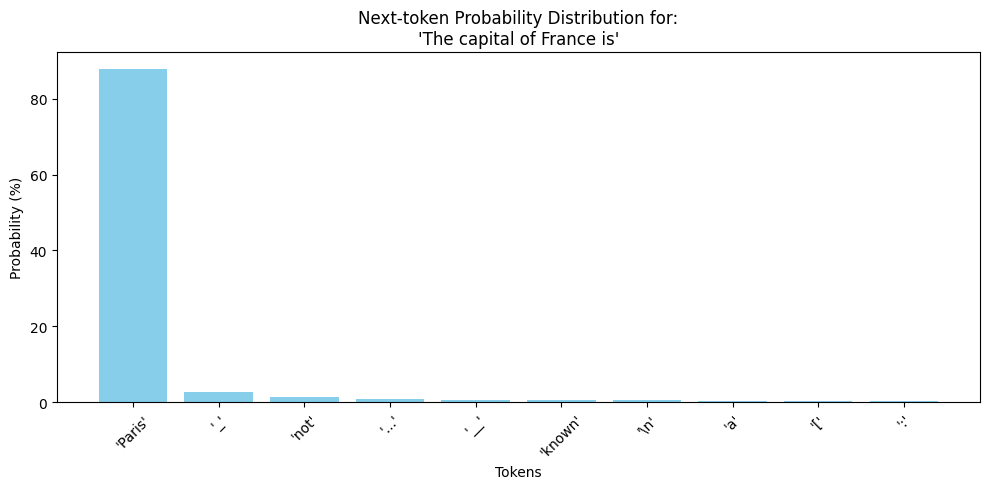

In [47]:
print(f"\nNext-token predictions for '{prompt}':")
for prob, token_id in zip(top_probs, top_ids):
    token_str = repr(tokenizer.decode([token_id]))
    print(f"{token_str:<15} | Probability: {prob.item()*100:6.2f}%")


import matplotlib.pyplot as plt

# Extract token strings and probabilities as lists
tokens = [repr(tokenizer.decode([token_id])) for token_id in top_ids]
probabilities = [prob.item() * 100 for prob in top_probs]

# Create a bar chart
plt.figure(figsize=(10, 5))
plt.bar(tokens, probabilities, color='skyblue')
plt.xlabel('Tokens')
plt.ylabel('Probability (%)')
plt.title(f"Next-token Probability Distribution for:\n'{prompt}'")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#temperature control


In [69]:
prompt = "<|user|>\nWrite a poem about NLP for 1st graders.<|end|>\n<|assistant|>\n"
inputs = tokenizer(prompt, return_tensors="pt").to("cuda")

In [70]:
configs = [
    {"name": "Greedy (Deterministic)", "do_sample": False},
    {"name": "Low Temp (Focused)", "do_sample": True, "temperature": 0.2, "top_p": 0.9},
    {"name": "High Temp (Chaotic)", "do_sample": True, "temperature": 1.5, "top_p": 0.95},
]
for cfg in configs:
    name = cfg.pop("name")
    output_ids = model.generate(
        **inputs,
        max_new_tokens=100,
        pad_token_id=tokenizer.eos_token_id,
        **cfg
    )
    # Slice off the input prompt tokens so we only decode newly generated tokens
    new_tokens = output_ids[0][inputs["input_ids"].shape[1]:]
    print(f"=== {name} ===")
    print(tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), "\n")

=== Greedy (Deterministic) ===
In a world of words, so vast and wide,
Where language and meaning coincide,
There's a magic trick, oh so neat,
That helps us understand, and not miss a beat.

It's called NLP, a wondrous tool,
That helps us learn, and not be a fool.
It's like a map, that guides us through,
The maze of words, and what they mean to you. 

=== Low Temp (Focused) ===
In a world of words and sounds,
Where language is all around,
There's a magic trick that's quite profound,
It's called NLP, it's all about.

It helps computers understand,
The words we speak, hand in hand,
And learn from us, just as we planned,
To make our communication grand.

With NLP, computers can learn,
To recognize our words, discern,
The meaning 

=== High Temp (Chaotic) ===
Nature language, oh so fun,
Helping robots to talk about,
Words that we use each day,
When we chat or laugh, or say,
Bye-bye on mama, see you.

Oh neural network patterns,
Spelling, rhymes, and stories to tell,
Making connections where

#KV caching


In [71]:
import time

prompt = "<|user|>\nExplain how a CPU cache works in simple terms.<|end|>\n<|assistant|>\n"
inputs = tokenizer(prompt, return_tensors="pt").to("cuda")

for use_cache in [True, False]:
    torch.cuda.synchronize()
    start = time.perf_counter()

    _ = model.generate(
        **inputs,
        max_new_tokens=150,
        do_sample=False,
        use_cache=use_cache
    )

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    print(f"use_cache={str(use_cache):<5} | Time: {elapsed:.3f}s | Speed: {150/elapsed:.1f} tokens/sec")

use_cache=True  | Time: 7.851s | Speed: 19.1 tokens/sec
use_cache=False | Time: 51.925s | Speed: 2.9 tokens/sec
